# 05 — Final model: calibration, explainability, test set

The final steps on the **candidate final model: LightGBM tuned v2**
(`tuning/results/v2/best_params.json`, chosen in `notebooks/04_lightgbm.ipynb`
and section 3b-v2 of `docs/findings_log.md`), with the logistic regression as
the transparent benchmark.

**Scripts run, this notebook explains.** Every number here is produced by a
script in `src/` and saved in `reports/`; this notebook only reads those files
and comments on them (no training here).

| Section | Command (from the project root) | Output | Status |
|---|---|---|---|
| 1. Calibration of LightGBM v2 | `python3 -m src.evaluate calibration` | `reports/calibration_dev.json`, `reports/calibration_lightgbm_comparison.png` | done (development set) |
| 2. Explainability (SHAP) | `python3 -m src.evaluate shap` | `reports/shap_dev.json`, `reports/figures/shap_*_dev.png` | done (development set) |
| 3. Test set, once | `python3 -m src.evaluate test` | `reports/test_results.json`, `reports/figures/test_*.png` | done: see `notebooks/07_test.ipynb` |

Sections 1 and 2 use the **development set only** (out-of-fold predictions);
the test set is opened **once**, in section 3.

Course sessions used: **S7** calibration (reliability diagram, Brier, ECE,
Platt, isotonic); **S8** explainability; **S5** honest evaluation on held-out
data.

In [1]:
import json
import sys
from pathlib import Path
import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
sys.path.insert(0, str(ROOT))
REPORTS = ROOT / "reports"

## 1. Calibration of LightGBM v2 (S7)

**Question:** when LightGBM v2 says "30%", are about 30% of those people really
high earners? The ranking metrics (PR-AUC, ROC-AUC) cannot answer this; the
reliability diagram, the Brier score and the ECE can.

**Protocol** (`src/evaluate.py`, with `BEST_PARAMS_VERSION = "v2"` in
`src/config.py`):
- every person in the development set gets an **out-of-fold** probability
  (scored by a model that never saw them), same 5 folds as the tuning;
- **Brier** = mean squared gap between the probability and the true label
  (0/1); lower is better;
- **ECE** = the gap between predicted and observed rates, averaged over 10 bins
  of equal size (1/10 of the people each), weighted by bin size; 0 = perfect;
- **recalibration:** Platt scaling (a logistic curve on the model's score, two
  parameters) and isotonic regression (a free non-decreasing step function).
  Each calibrator is scored by a **second** 5-fold CV on the out-of-fold
  predictions, so it is never scored on the rows it was fitted on;
- the same checks **by sex** (S7: "check calibration by segment").

The script calibrates the three tuned v2 models together; this section reads
the LightGBM rows, with the other two models' raw probabilities as context.

In [2]:
calib = pd.read_json(REPORTS / "calibration_dev.json")
lgbm = calib[calib["model"] == "LightGBM"]
print("LightGBM v2, all people (out-of-fold, development set)")
display(lgbm[lgbm["group"] == "all"][["variant", "brier", "ece", "pr_auc", "roc_auc",
                                       "top_bin_predicted", "top_bin_observed"]].round(4))
print("LightGBM v2, by sex")
display(lgbm[lgbm["group"] != "all"][["variant", "group", "brier", "ece",
                                       "mean_predicted", "observed_rate"]].round(4))
print("Raw probabilities of the three tuned v2 models, all people")
display(calib[(calib["variant"] == "raw") & (calib["group"] == "all")]
        [["model", "brier", "ece", "pr_auc", "top_bin_predicted", "top_bin_observed"]].round(4))

LightGBM v2, all people (out-of-fold, development set)


,variant,brier,ece,pr_auc,roc_auc,top_bin_predicted,top_bin_observed
18,raw,0.1096,0.0058,0.7183,0.8927,0.8069,0.8122
21,platt,0.1096,0.0057,0.7180,0.8927,0.8071,0.8110
24,isotonic,0.1097,0.0010,0.7135,0.8919,0.8147,0.8139


LightGBM v2, by sex


,variant,group,brier,ece,mean_predicted,observed_rate
19,raw,Female,0.0608,0.0100,0.1122,0.1094
20,raw,Male,0.1337,0.0099,0.3024,0.3037
22,platt,Female,0.0608,0.0100,0.1121,0.1094
23,platt,Male,0.1337,0.0102,0.3024,0.3037
25,isotonic,Female,0.0609,0.0115,0.1121,0.1094
26,isotonic,Male,0.1338,0.0065,0.3024,0.3037


Raw probabilities of the three tuned v2 models, all people


,model,brier,ece,pr_auc,top_bin_predicted,top_bin_observed
0,Logistic Regression,0.1113,0.0059,0.7080,0.8175,0.8038
9,Random Forest,0.1104,0.0109,0.7142,0.7895,0.8099
18,LightGBM,0.1096,0.0058,0.7183,0.8069,0.8122


**LightGBM v2: raw (baseline) vs Platt vs isotonic.** Reliability curve on top
(the raw curve in grey as the reference in the two recalibrated panels),
distribution of the predicted probabilities below.

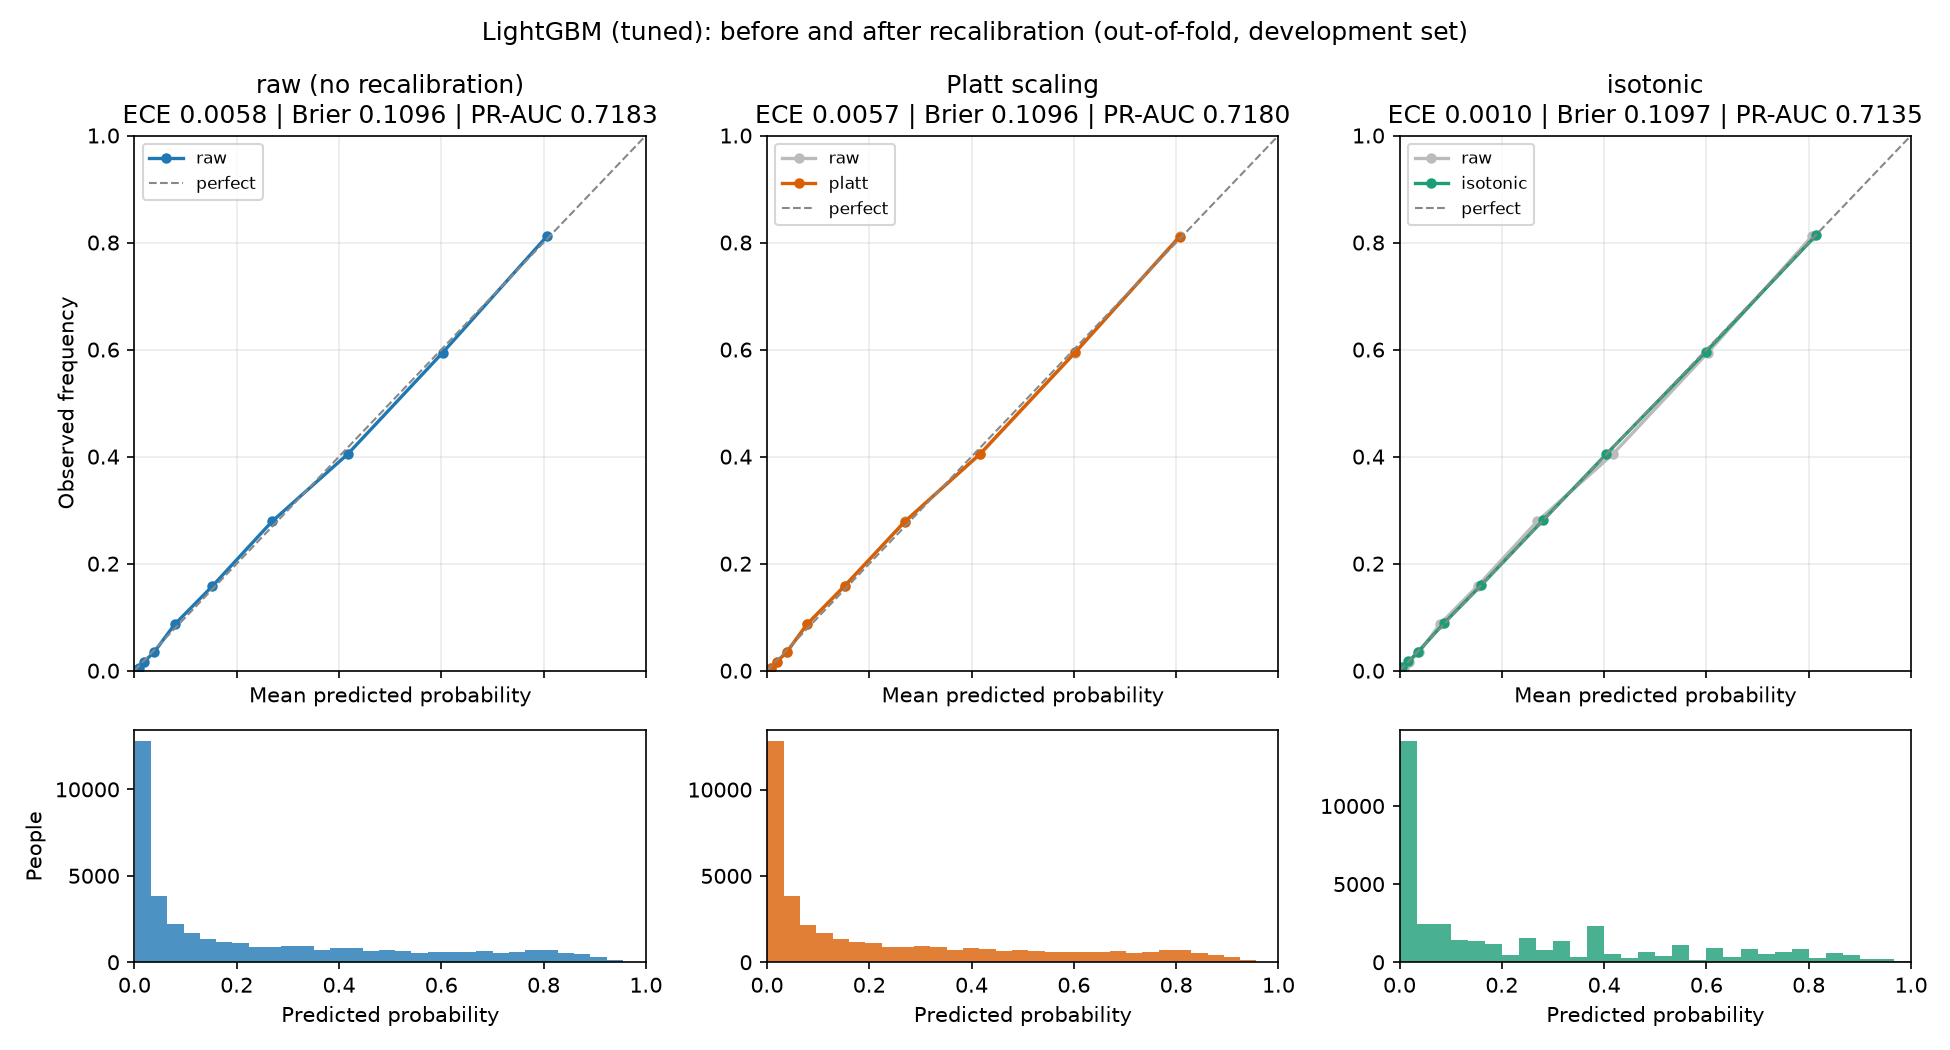

In [3]:
display(Image(str(REPORTS / "calibration_lightgbm_comparison.png")))

### Reading

(v1 numbers: findings F22-F24 in `docs/findings_log.md`, same script on the v1
parameters.)

- **LightGBM v2 is already calibrated, before any recalibration.** Raw ECE
  0.0058 (v1: 0.030), the level of the logistic regression (0.0059); Brier
  0.1096, the lowest of the three models. The reliability curve sits on the
  diagonal. In the top 10%, the model predicts 0.807 and 0.812 are high
  earners (v1: 0.835 vs 0.813, over-confident).
- **Why:** v1 used `scale_pos_weight` 1.32, which counts every high earner
  1.32 times in the loss and so pushes every probability up. v2 fixes it at 1
  (notebook 04, section 3), so LightGBM minimises the plain log-loss, whose
  minimum is reached by true probabilities (S7). The random forest tells the
  same story: removing its class weights took its ECE from 0.132 (v1) to
  0.011 (v2).
- **Platt scaling now does nothing:** ECE 0.0057, Brier 0.1096, PR-AUC 0.7183
  → 0.7180. There is nothing left to correct.
- **Isotonic gives the lowest ECE (0.0010) but costs ranking** (PR-AUC 0.7183 →
  0.7135): its step function gives the same probability to many people (ties).
  The figure shows it: the raw and Platt histograms are smooth and almost
  identical, the isotonic one is spiky, while the three reliability curves lie
  on top of each other. Not worth it when the raw model is already calibrated.
- **By sex, the raw probabilities mean the same for women and men on
  average:** women predicted 0.112 vs observed 0.109, men 0.302 vs 0.304 (v1:
  0.132 vs 0.109 and 0.337 vs 0.304, over-predicted for both and more for
  women in relative terms). ECE 0.010 for both groups. The Brier score is lower
  for women (0.061 vs 0.134) only because their base rate is lower, not
  because their probabilities are better.
- **Note on PR-AUC:** 0.7183 here vs 0.7189 in notebook 04. Here the PR-AUC is
  computed once on all pooled out-of-fold predictions; in notebook 04 it is the
  mean of the 5 per-fold values. Both are correct; they measure slightly
  different things.
- **Caveat:** the parameters were tuned on these same folds, so these numbers
  are slightly optimistic (S5). The calibration is checked once more on the
  test set (section 3).

**Decision:** LightGBM v2 does **not need recalibration**; its raw
probabilities are used as they are. `src/fairness.py` still applies Platt to
LightGBM: with v2 this is harmless (same probabilities), to keep or remove as a
team decision. Details: finding F41 in `docs/findings_log.md`.

## 2. Explainability: SHAP on LightGBM v2 (S8)

**Questions:** which inputs drive the predictions of LightGBM v2? And, for the
audit: which inputs make the scores of women lower than those of men, although
`sex` is never an input? (Project hypothesis: marital status, occupation and
hours act as proxies for sex, F30-F31.)

**What a SHAP value is.** For one person, the SHAP value of a column is how
much that column moves the model's score away from the average score (the
*base value*), in **log-odds** (LightGBM's raw score, before the sigmoid).
Positive = pushes towards "> $50K", negative = away from it. For every person:

> score = base value + sum of the SHAP values of all columns

so SHAP values can be **added**: the 37 columns after preprocessing are added
back into the **6 model inputs** (all one-hot categories of an input, plus the
engineered columns made from it: `is_married` → marital status, `has_degree` →
education, `part_time` / `overtime` → hours, `age_squared` → age), and the
**mean score gap between women and men splits exactly into one part per input**.

**Protocol** (`src/evaluate.py`, stage `shap`):
- out-of-fold, like the calibration: in each of the 5 folds the Pipeline is
  fitted on the other folds and **TreeSHAP** (exact for tree models) explains
  the held-out people. All 39,032 people of the development set are explained
  by a model that never saw them; the test set is not used;
- Platt scaling is applied after the score and is monotone, so it does not
  change these explanations (and on v2 it is practically the identity,
  section 1).

LightGBM v2, 39,032 people, units: log-odds (LightGBM raw score); mean base value -2.198

Per model input: mean |SHAP| (importance), by sex, and mean SHAP (direction)


,mean_abs,mean_abs_women,mean_abs_men,mean_women,mean_men,gap_women_minus_men
input,,,,,,
marital-status,1.1960,1.1535,1.2170,-0.7215,0.3674,-1.0889
age,0.7375,0.8348,0.6894,-0.1501,0.0753,-0.2253
education-num,0.5153,0.4621,0.5415,-0.0169,0.0068,-0.0238
hours-per-week,0.3534,0.3880,0.3363,-0.1622,0.0772,-0.2393
occupation,0.3388,0.3565,0.3300,-0.0444,0.0122,-0.0566
workclass,0.0805,0.0658,0.0877,-0.0109,0.0096,-0.0205


Top 15 columns after preprocessing


,column,input,mean_abs,mean
0,marital-status_Married-civ-spouse,marital-status,0.7070,0.0010
1,age,age,0.4808,-0.0004
2,education-num,education-num,0.4116,0.0022
3,is_married,marital-status,0.3555,-0.0011
4,age_squared,age,0.2571,0.0010
5,hours-per-week,hours-per-week,0.2146,-0.0016
6,occupation_Exec-managerial,occupation,0.1358,-0.0056
7,marital-status_Never-married,marital-status,0.1319,0.0040
8,has_degree,education-num,0.1315,-0.0032
9,occupation_Other-service,occupation,0.1134,-0.0031


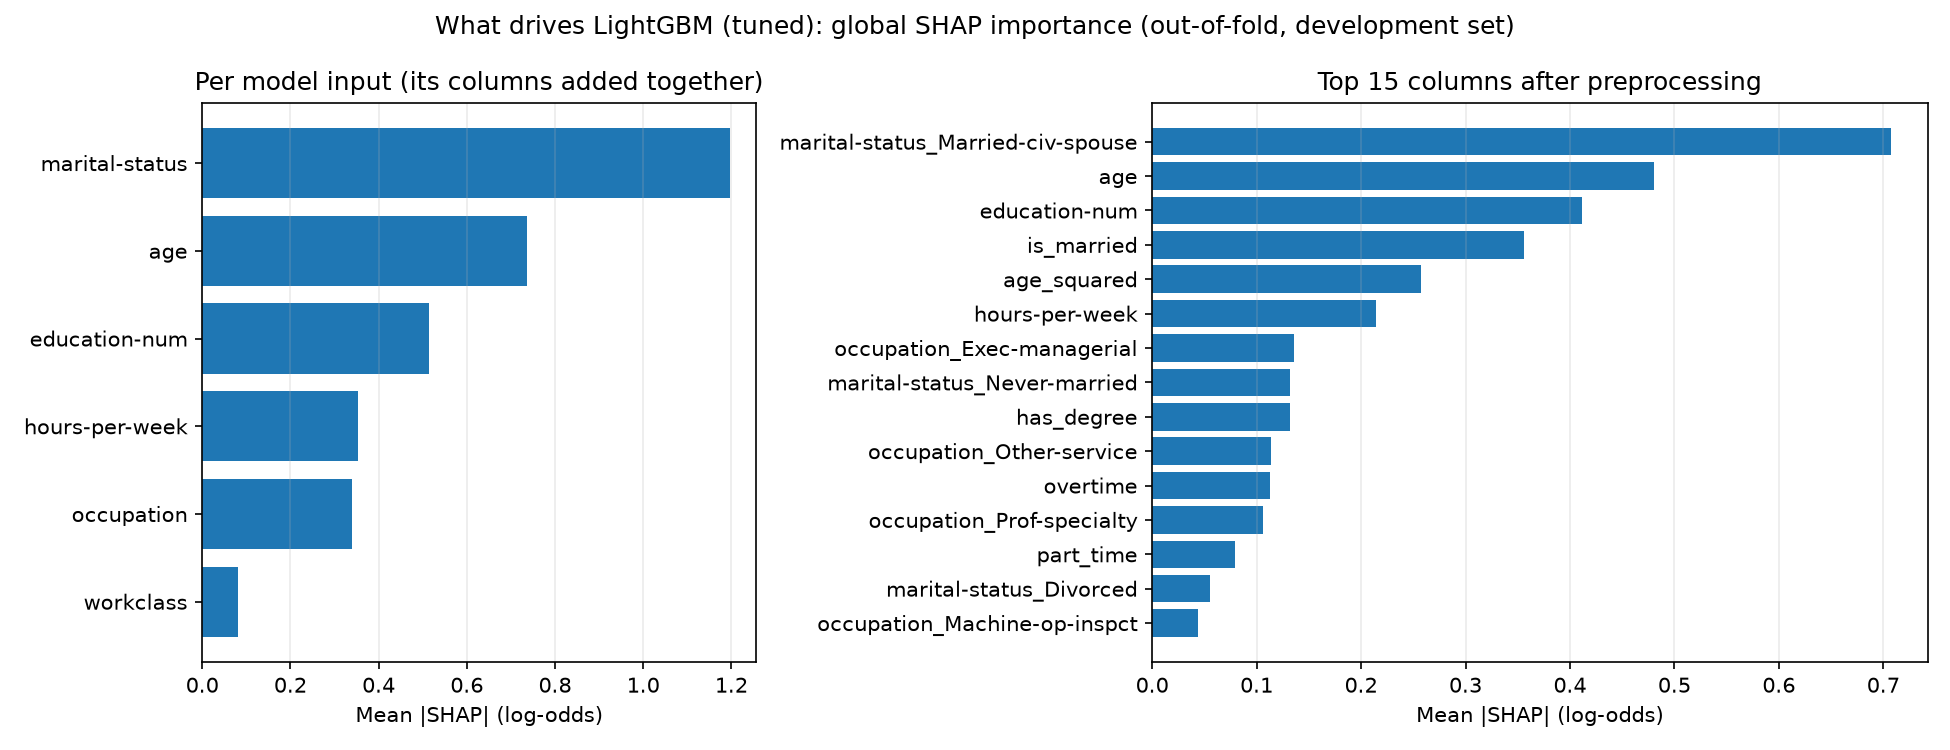

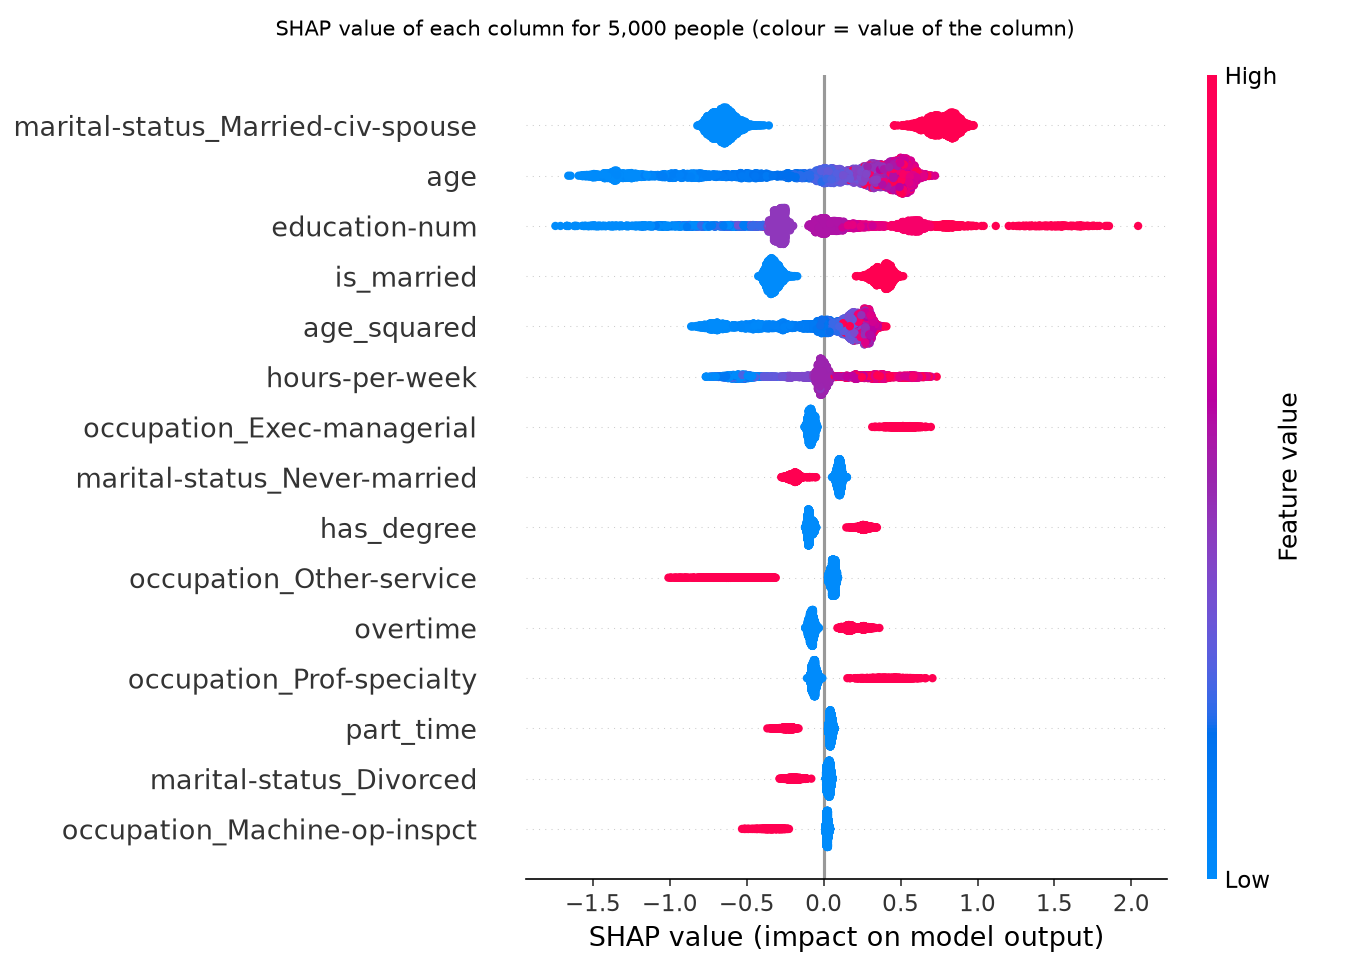

In [4]:
shap_res = json.loads((REPORTS / "shap_dev.json").read_text())
by_input = pd.DataFrame(shap_res["by_input"]).set_index("input")
print(f"{shap_res['model']} {shap_res['version']}, {shap_res['n_people']:,} people, "
      f"units: {shap_res['units']}; mean base value {shap_res['base_value_mean']:.3f}")
print("\nPer model input: mean |SHAP| (importance), by sex, and mean SHAP (direction)")
display(by_input.round(4))
print("Top 15 columns after preprocessing")
display(pd.DataFrame(shap_res["by_column"]).head(15).round(4))
display(Image(str(REPORTS / "figures" / "shap_importance_dev.png")))
display(Image(str(REPORTS / "figures" / "shap_beeswarm_dev.png")))

**Global reading.**
- **Marital status is by far the strongest input** (mean |SHAP| 1.20
  log-odds), then age (0.74), education (0.52), hours (0.35), occupation (0.34);
  workclass hardly matters (0.08). The same order as the EDA signals (F9) and
  as the order in which Lasso keeps the columns (F37).
- **Being married (Married-civ-spouse) is the single strongest column** (0.71;
  with its copy `is_married`, 0.36): in the beeswarm, married people get about
  +0.8 log-odds, unmarried people about −0.6. The trees split the effect
  between the two identical columns arbitrarily, so only their sum (the
  marital-status input) should be read.
- **The directions are the expected ones:** more education, a managerial or
  professional occupation, more hours and middle age raise the score;
  `Other-service`, `Machine-op-inspct`, part-time work and being young lower it.

Mean score (log-odds): women -3.304, men -1.650, gap -1.654
= sum of the input parts -1.654 + base value 0.00001


,mean_women,mean_men,gap_women_minus_men,share of the gap
input,,,,
marital-status,-0.721,0.367,-1.089,0.658
hours-per-week,-0.162,0.077,-0.239,0.145
age,-0.150,0.075,-0.225,0.136
occupation,-0.044,0.012,-0.057,0.034
education-num,-0.017,0.007,-0.024,0.014
workclass,-0.011,0.010,-0.020,0.012


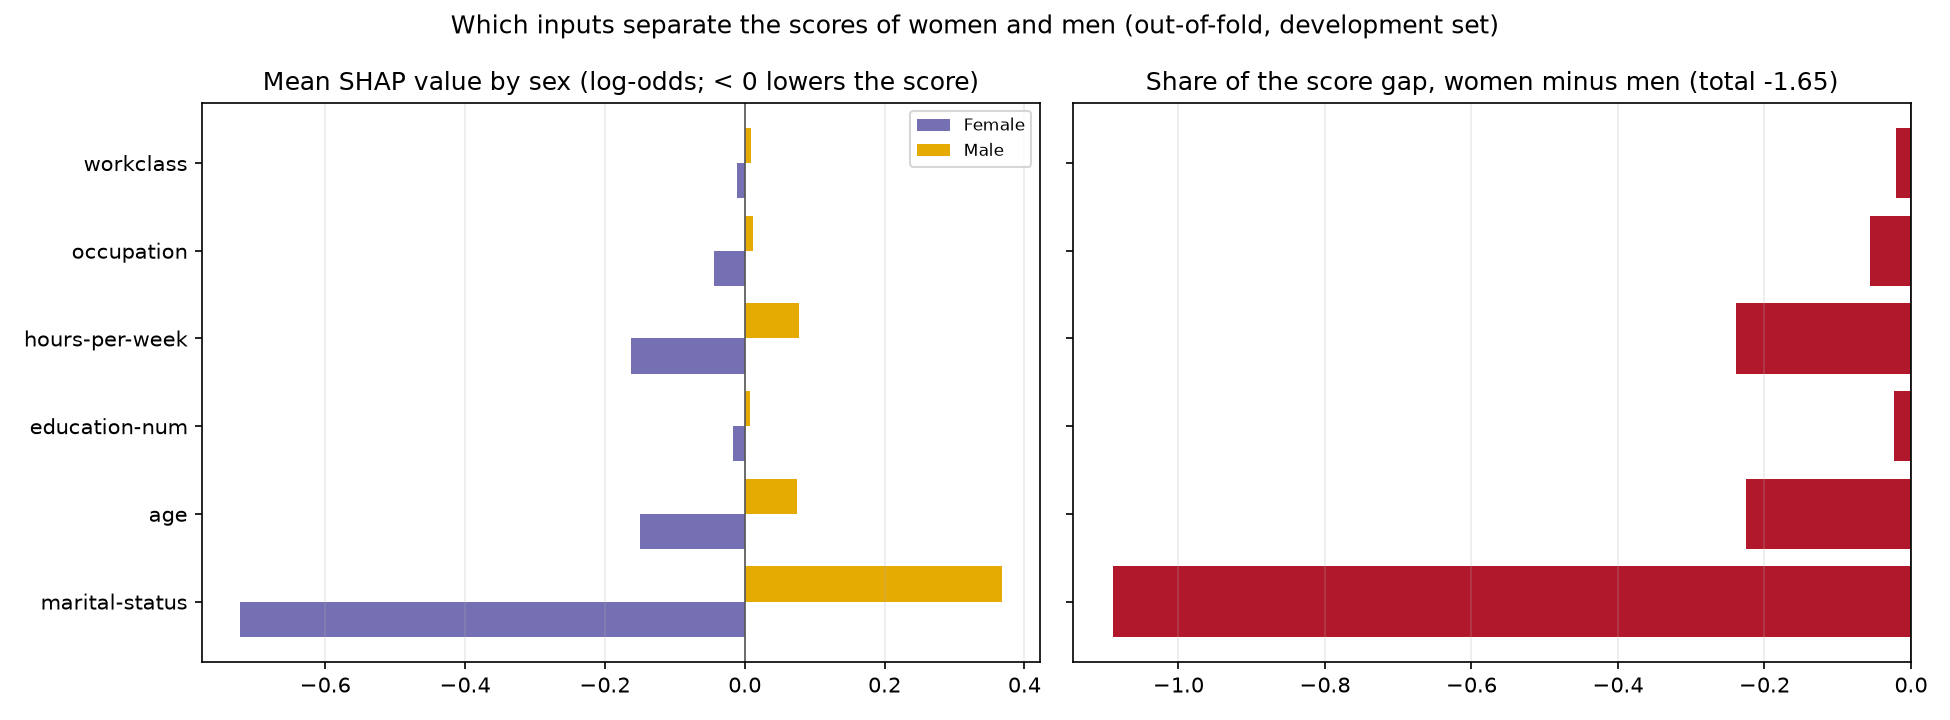

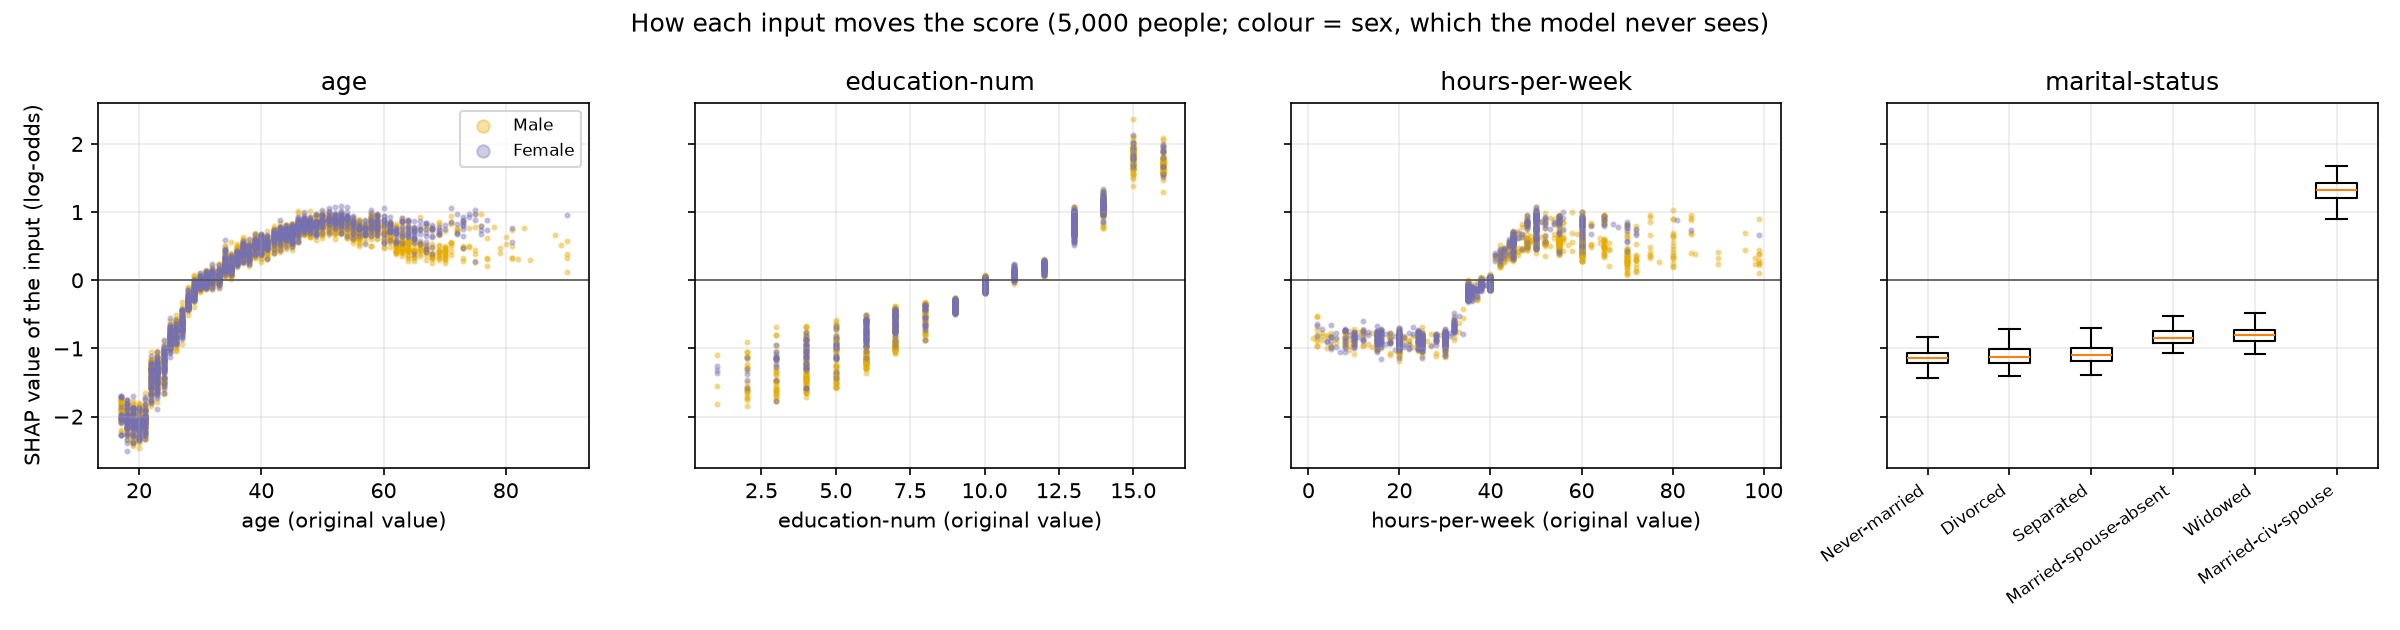

In [5]:
gap = shap_res["score_gap_by_sex"]
print(f"Mean score (log-odds): women {gap['mean_score_women']:.3f}, men {gap['mean_score_men']:.3f}, "
      f"gap {gap['score_gap']:.3f}")
print(f"= sum of the input parts {gap['sum_of_input_gaps']:.3f} + base value {gap['base_value_gap']:.5f}")
share = (by_input["gap_women_minus_men"] / gap["score_gap"]).rename("share of the gap")
display(pd.concat([by_input[["mean_women", "mean_men", "gap_women_minus_men"]], share], axis=1)
        .sort_values("gap_women_minus_men").round(3))
display(Image(str(REPORTS / "figures" / "shap_by_sex_dev.png")))
display(Image(str(REPORTS / "figures" / "shap_dependence_dev.png")))

**Reading by sex: where the score gap between women and men comes from.**
- **The mean score of women is 1.65 log-odds lower than that of men** (−3.30
  vs −1.65), although `sex` is not an input. SHAP splits this gap exactly
  (the base value is the same for both, gap 0.00001):
  **marital status 66%** (−1.09), **hours 14%** (−0.24), **age 14%** (−0.23),
  occupation 3% (−0.06), education 1% (−0.02), workclass 1% (−0.02).
- **Marital status is the main proxy for sex.** It pushes women's scores down
  by 0.72 on average and men's up by 0.37, because 60.9% of the men are
  Married-civ-spouse vs 15.3% of the women (F30). This is the hypothesis of
  the project, now measured on the model: two thirds of the gap goes through
  marriage.
- **Hours and age come next:** women work fewer hours (36.4 vs 42.4 on
  average, F30) and are younger in these data (mean age 36.9 vs 39.5, median
  35 vs 38, development set); both lower their scores.
- **Education explains almost none of the gap** (1%), although it is the third
  most important input overall: it separates people, but not women from men.
- **The same value has about the same effect for women and men** (dependence
  figure: the purple and yellow points mostly overlap). The model does not
  treat a married woman differently from a married man; the gap comes from the
  different values women and men have. This fits F31: among married people the
  share of high earners is the same for women and men (44.8% vs 44.6%), so the
  marriage effect itself matches the data; among unmarried people women earn
  less (4.8% vs 8.2%).
- **Link with the fairness audit (notebook 06):** a lower score for women at
  one common threshold gives a lower selection rate and a lower TPR for women.
  SHAP shows *which* inputs carry that difference; the audit shows its
  *consequences* on the decisions.
- **Caveats:** SHAP describes the model, not causes in the world (S8). Duplicate
  columns (`is_married` / Married-civ-spouse, `workclass_Unknown` /
  `occupation_Unknown`) share their effect arbitrarily: read the inputs, not
  these single columns. The dependence plots show a sample of 5,000 people.

**Decision:** no input is removed. Dropping marital status would remove the
strongest legitimate signal and the proxy effect would partly move to the
other inputs (age, hours, occupation also differ by sex). The bias is handled
at the decision step (equalized odds, notebook 06) and reported. Details:
finding F43 in `docs/findings_log.md`.

## 3. Test set, once: see `notebooks/07_test.ipynb`

The final evaluation on the locked test set (9,758 people) is in its own
notebook, `notebooks/07_test.ipynb` (finding F44). In short, for LightGBM v2:
PR-AUC 0.715 [0.696, 0.732] (development 0.718), ROC-AUC 0.894, Brier 0.109,
ECE 0.009 (still calibrated, also by sex); better than the logistic regression
(+0.011 PR-AUC, paired interval excludes 0), tied with the random forest. The
bias by sex is confirmed (TPR 0.570 vs 0.785, four-fifths ratio 0.28), the
equalized-odds mitigation fixed on the development set brings both error-rate
gaps to about 0, and marital status still carries two thirds of the score gap.